# Entrega Final TP Diplomatura Data Science
### Predicción de churn bancario y priorización comercial de retención
**UTN — Diplomatura en Ciencia de Datos y Análisis Avanzado · Proyecto Final Integrador**  
**Grupo 53:** Julian Appella · Cintia Opaso · Leonardo Caporossi · Mariangeles Fontela  
**Versión final para revisión grupal · octubre de 2026**

**Punto de partida:** este Trabajo Final Integrador continúa la **preentrega presentada el 21/09/2026**, evaluada con **90/100**. Se mantiene el problema de churn bancario, el dataset y los cuatro algoritmos allí propuestos, y se incorporan las observaciones del docente sobre validación, métricas, selección del modelo e interpretación de negocio.

**Guía de ejecución:** en Google Colab elegir `Entorno de ejecución → Ejecutar todas`. Si el CSV no está disponible, se solicita subir `Churn Modeling.csv`. En Python/Jupyter local, dejar ese archivo junto al notebook. Los resultados, gráficos y archivos de salida se regeneran al ejecutar.

**Alcance:** `Exited` identifica un estado de abandono observado en datos sin fechas. Por lo tanto, **no se afirma una predicción validada a 12 meses**. Detectar riesgos tampoco prueba que una campaña comercial evite bajas.

## 1. Continuidad de la preentrega y correcciones incorporadas

La **preentrega del Grupo 53 (21/09/2026)** definió un problema de clasificación binaria de abandono bancario, una tasa base de churn del **20,37%** (2.037 de 10.000 clientes), el uso de un dataset público mencionado como procedente de Kaggle y un plan para comparar **Regresión Logística, SVM RBF, Árbol de Decisión y LightGBM**. Esa preentrega citaba resultados de **trabajos técnicos anteriores del propio grupo**, pero no presentaba todavía una evaluación final completa ni un procedimiento de selección suficientemente explicitado.

**La devolución docente (90/100) consideró viable el proyecto** y solicitó completar cinco puntos:

| Observación del docente | Cómo se resuelve en esta entrega |
|:--|:--|
| Precisar la validación | Partición **train/test estratificada 80/20** y validación cruzada de cinco folds dentro de train. |
| Informar métricas adecuadas | **Precision, Recall, F1 y PR-AUC (Average Precision)**, además de ROC-AUC y matrices de confusión. |
| Comparar y defender al ganador | Regla común: mayor **F1 en predicciones out-of-fold (OOF)**; desempate por PR-AUC, con test reservado. |
| Traducir el resultado a Retención | Medir qué porcentaje de abandonos se identifica al priorizar el **20% de mayor score**. |
| Corregir el horizonte temporal | No se afirma churn «a 12 meses», porque faltan fechas. |

**Qué evolucionó desde la preentrega:** se formalizó el proceso experimental, se ajustan los umbrales con el entrenamiento y se cuantifica la priorización comercial en test. Se conserva el mismo tema y las mismas familias de algoritmos, pero las predicciones no son necesariamente idénticas a las de trabajos previos porque cambian algunas configuraciones y transformaciones.

**Qué no se hace:** no se repiten las búsquedas históricas de hiperparámetros (`GridSearchCV`) ni se agregan algoritmos nuevos. Esas búsquedas se documentan como **antecedentes técnicos citados por la preentrega**, no como experimentos efectuados durante esta ejecución. Esto no elimina la validación cruzada que sí se aplica a los cuatro modelos.

## 2. Comprensión del negocio y métricas de éxito (CRISP-DM)
**Pregunta del banco hipotético:** si Retención solamente puede contactar al **20% de la cartera**, ¿qué proporción de los clientes que abandonaron queda incluida en ese grupo priorizado?

- **Variable objetivo:** `Exited = 1` (abandona), `Exited = 0` (permanece). Clasificación binaria supervisada.
- **Indicador descriptivo base:** tasa de abandono observada; no es una tasa futura estimada.
- **Criterio técnico principal para elegir modelo:** **F1-score de Exited=1** en predicciones OOF de validación cruzada, con umbral obtenido en entrenamiento; desempate por Average Precision (AP o resumen PR-AUC).
- **Evaluaciones complementarias:** Precision, Recall, ROC-AUC, Average Precision (PR-AUC) y matriz de confusión en test.
- **Indicador de negocio:** **Recall@20%**, proporción de abandonos reales incluidos entre el 20% con score más alto. Referencia de selección al azar ≈ 20%.
- **Metas orientativas para el ejercicio:** F1 de test ≥ 0,60 y Recall@20% mayor que 20%. Son criterios exploratorios definidos para este trabajo; no objetivos acordados con un banco real.

**CRISP-DM:** (1) negocio → (2) comprensión de datos → (3) preparación → (4) modelado → (5) evaluación → (6) propuesta de uso controlado. No se afirma despliegue en producción ni ahorro monetario.

In [ ]:
# Librerías y semillas. En Colab, LightGBM suele estar instalado; si falta, se instala.
import sys, subprocess, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (precision_recall_curve, precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score, confusion_matrix, classification_report)
try:
    from lightgbm import LGBMClassifier
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'lightgbm'])
    from lightgbm import LGBMClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.rcParams.update({'figure.dpi':120, 'axes.spines.top':False, 'axes.spines.right':False})
print('Dependencias preparadas.')

Dependencias preparadas.


## 3. Dataset utilizado en la preentrega y controles de reproducibilidad
**Fuente:** `Churn Modeling.csv`, mencionado en la **preentrega aprobada** como dataset público procedente de Kaggle. El grupo ya había analizado su estructura en trabajos previos. **La URL exacta, la licencia y la procedencia primaria no se han acreditado** en los materiales compartidos; deben verificarse antes de publicar el proyecto.

**Entrada esperada:** 10.000 registros y 14 columnas. Se comprueban las columnas requeridas y que `Exited` sea binaria. No se utilizan rutas personales de Google Drive ni se presupone que los datos representan una cartera bancaria real y actual.

In [ ]:
# Buscar primero el CSV en la carpeta de trabajo; en Colab subirlo solo si falta.
candidatos = list(Path('.').glob('Churn Modeling*.csv'))
if not candidatos:
    try:
        from google.colab import files
    except ImportError as e:
        raise FileNotFoundError('Colocá Churn Modeling.csv junto al notebook.') from e
    print('Subí el archivo original Churn Modeling.csv para continuar.')
    uploaded = files.upload()
    candidatos = [Path(x) for x in uploaded if x.lower().endswith('.csv')]
    if not candidatos:
        raise FileNotFoundError('No se recibió Churn Modeling.csv.')
csv_path = sorted(candidatos, key=lambda x: len(x.name))[0]

df = pd.read_csv(csv_path)
requeridas = ['RowNumber','CustomerId','Surname','CreditScore','Geography','Gender',
             'Age','Tenure','Balance','NumOfProducts','HasCrCard','IsActiveMember',
             'EstimatedSalary','Exited']
faltantes = sorted(set(requeridas) - set(df.columns))
if faltantes: raise ValueError(f'Faltan columnas: {faltantes}')
if not set(df['Exited'].dropna().unique()).issubset({0,1}): raise ValueError('Exited debe ser binaria: 0/1.')
print(f'Datos: {df.shape[0]:,} registros y {df.shape[1]} columnas | Archivo: {csv_path}')
display(df.head(3))

Datos: 10,000 registros y 14 columnas | Archivo: Churn Modeling.csv


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1


## 4. Calidad de datos y análisis exploratorio (EDA)
Se recuperan y se comprueban los hallazgos que fundamentaron la **preentrega**: nulos, duplicados, prevalencia de abandono y segmentos relevantes. No se imputan saldos cero ni se eliminan edades extremas válidas. Las columnas `RowNumber`, `CustomerId` y `Surname` se excluyen del modelado. Se añade `BalanceZero` como indicador derivado del saldo, sin utilizar información de `Exited`.

Duplicados completos: 0 | CustomerId duplicados: 0
Prevalencia de churn: 20.37% | Clientes churn: 2037


,nulos,valores_unicos
RowNumber,0,10000
CustomerId,0,10000
Surname,0,2932
CreditScore,0,460
Geography,0,3
Gender,0,2
Age,0,70
Tenure,0,11
Balance,0,6382
NumOfProducts,0,4



Segmento Geography


,clientes,churn
Geography,,
France,5014,0.1615
Germany,2509,0.3244
Spain,2477,0.1667



Segmento Gender


,clientes,churn
Gender,,
Female,4543,0.2507
Male,5457,0.1646



Segmento NumOfProducts


,clientes,churn
NumOfProducts,,
1,5084,0.2771
2,4590,0.0758
3,266,0.8271
4,60,1.0000



Segmento IsActiveMember


,clientes,churn
IsActiveMember,,
0,4849,0.2685
1,5151,0.1427


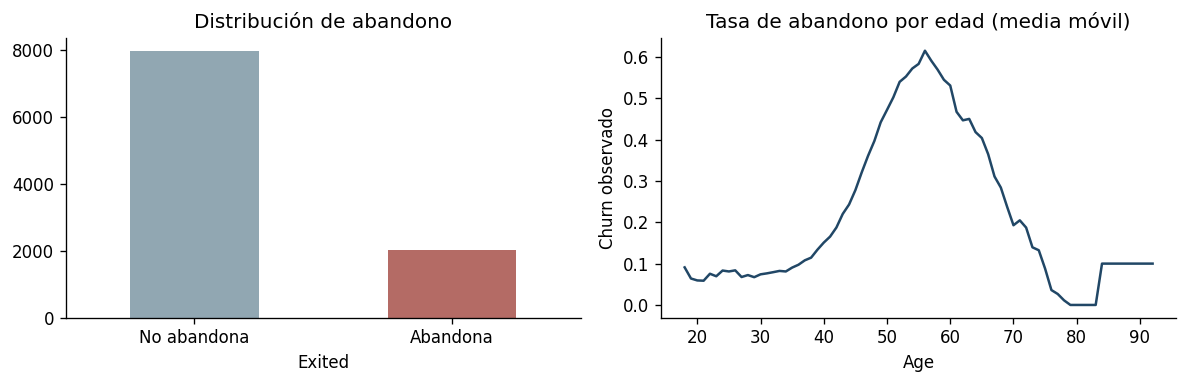

In [ ]:
control = pd.DataFrame({'nulos': df.isna().sum(), 'valores_unicos': df.nunique()})
print('Duplicados completos:', df.duplicated().sum(), '| CustomerId duplicados:', df.CustomerId.duplicated().sum())
print('Prevalencia de churn:', f'{df.Exited.mean():.2%}', '| Clientes churn:', int(df.Exited.sum()))
display(control)
for var in ['Geography','Gender','NumOfProducts','IsActiveMember']:
    print('\nSegmento', var)
    display(df.groupby(var, dropna=False)['Exited'].agg(clientes='size',churn='mean').round(4))
fig, ax = plt.subplots(1,2,figsize=(10,3.3))
(df['Exited'].value_counts().sort_index()).plot.bar(ax=ax[0],color=['#91a7b2','#b46b65'])
ax[0].set_title('Distribución de abandono'); ax[0].set_xticklabels(['No abandona','Abandona'],rotation=0)
(df.groupby('Age')['Exited'].mean().rolling(5,min_periods=1).mean()).plot(ax=ax[1],color='#214766')
ax[1].set_title('Tasa de abandono por edad (media móvil)'); ax[1].set_ylabel('Churn observado')
plt.tight_layout(); plt.show()

### 4.1 EDA breve: edad, país y cantidad de productos
La **preentrega del 21/09** destacaba asociaciones entre abandono y **edad, geografía, cantidad de productos y actividad**. Aquí se recuperan tres vistas para mostrar los patrones que motivan el modelado, sin reproducir todo el análisis exploratorio realizado previamente.

- **Edad:** tasas observadas por franjas, para facilitar la interpretación.
- **País:** tasas por segmento, sin inferir relaciones causales ni recomendar trato diferencial automático.
- **Productos:** tasas y cantidad de clientes de cada grupo; los segmentos de 3–4 productos requieren cautela por su tamaño.

**Precaución:** el EDA describe el CSV completo, como en la preentrega. La selección de modelos, el ajuste de transformaciones y la validación se realizan con entrenamiento, sin usar el test para decidir el ganador.

Tasa de churn por tramo de edad:


,clientes,abandonos,tasa_churn
TramoEdad,,,
18–30,1968,148,0.0752
31–40,4451,538,0.1209
41–50,2320,788,0.3397
51–60,797,448,0.5621
61+,464,115,0.2478


Tasa de churn por país:


,clientes,abandonos,tasa_churn
Geography,,,
France,5014,810,0.1615
Germany,2509,814,0.3244
Spain,2477,413,0.1667


Tasa de churn por cantidad de productos:


,clientes,abandonos,tasa_churn
NumOfProducts,,,
1,5084,1409,0.2771
2,4590,348,0.0758
3,266,220,0.8271
4,60,60,1.0000


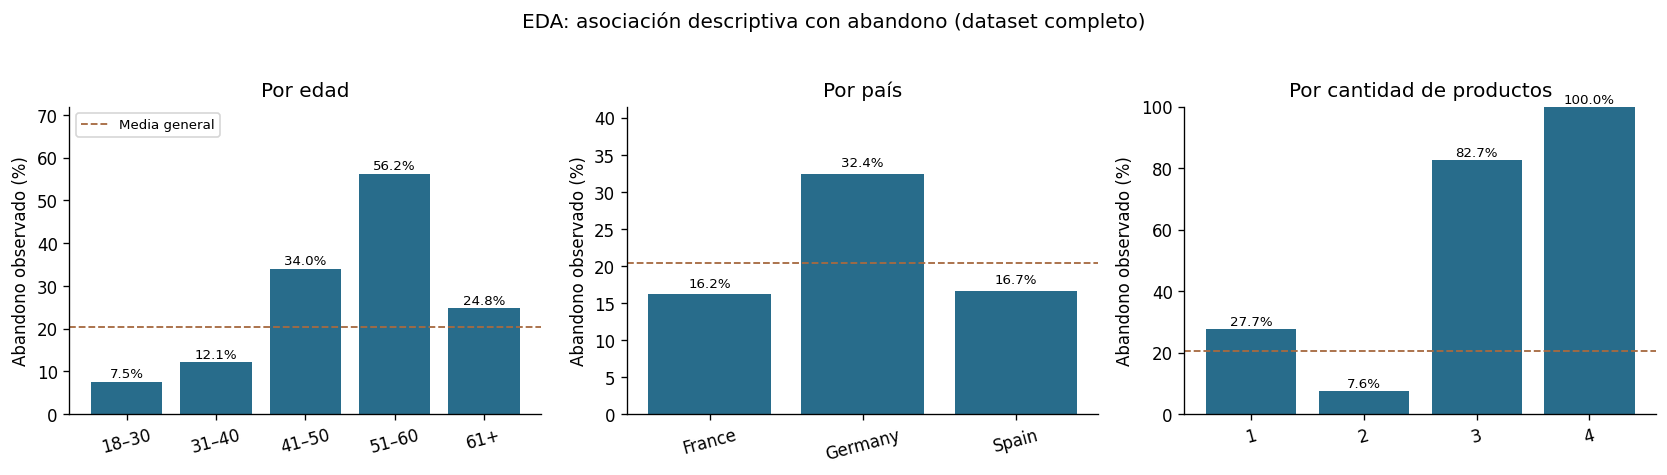

In [ ]:
# EDA descriptivo (no modifica variables, hiperparámetros ni métricas del modelo).
edades = pd.cut(df['Age'], bins=[17,30,40,50,60,float('inf')],
                labels=['18–30','31–40','41–50','51–60','61+'])
eda_edad = df.assign(TramoEdad=edades).groupby('TramoEdad',observed=True)['Exited'].agg(
    clientes='size', abandonos='sum', tasa_churn='mean')
eda_pais = df.groupby('Geography')['Exited'].agg(clientes='size',abandonos='sum',tasa_churn='mean')
eda_productos = df.groupby('NumOfProducts')['Exited'].agg(clientes='size',abandonos='sum',tasa_churn='mean')
print('Tasa de churn por tramo de edad:')
display(eda_edad.round(4))
print('Tasa de churn por país:')
display(eda_pais.round(4))
print('Tasa de churn por cantidad de productos:')
display(eda_productos.round(4))
fig, axes = plt.subplots(1,3,figsize=(14,3.8))
for ax, tabla, titulo in [
    (axes[0], eda_edad, 'Por edad'),
    (axes[1], eda_pais, 'Por país'),
    (axes[2], eda_productos, 'Por cantidad de productos')]:
    valores = tabla['tasa_churn']*100
    ax.bar([str(k) for k in valores.index],valores.values,color='#286c8b')
    ax.axhline(df.Exited.mean()*100,color='#a66a41',ls='--',lw=1.1,label='Media general')
    ax.set_title(titulo)
    ax.set_ylabel('Abandono observado (%)')
    ax.tick_params(axis='x', labelrotation=15)
    for i,v in enumerate(valores.values):
        ax.text(i,v+1,f'{v:.1f}%',ha='center',fontsize=8)
    ax.set_ylim(0, max(100 if max(valores.values)>80 else max(valores.values)*1.28,25))
axes[0].legend(loc='upper left',fontsize=8)
fig.suptitle('EDA: asociación descriptiva con abandono (dataset completo)',y=1.03)
plt.tight_layout()
plt.savefig('eda_segmentos.png',dpi=160,bbox_inches='tight')
plt.show()


### 4.2 Decisiones de preparación y pendientes de la preentrega
- **Nulos y duplicados:** el CSV analizado no los presenta, por lo que no se imputan ni eliminan registros.
- **Identificadores:** se excluyen `RowNumber`, `CustomerId` y `Surname` de las variables predictoras.
- **Saldos en cero:** se conservan como valores válidos y se añade `BalanceZero`; la **preentrega ya señalaba ese segmento**, aunque incorporar un indicador adicional al modelo es una decisión posterior y no una obligación docente.
- **Edad extrema:** se mantiene la edad máxima de 92 años al no existir evidencia de error.
- **`EstimatedSalary`:** la preentrega señalaba como pendiente evaluar su exclusión. En esta evaluación se conserva para mantener el experimento documentado; retirarla requeriría ejecutar y comparar una variante adicional.
- **Clientes con 3–4 productos:** la preentrega pedía revisar la sensibilidad del resultado. Más adelante se presenta una evaluación diagnóstica sin ese pequeño segmento.

## 5. Preparación y separación de entrenamiento y test
Se realiza un **train/test 80/20 estratificado** (semilla 42), conforme a la devolución docente. `StandardScaler` y `OneHotEncoder` se ajustan dentro de cada fold mediante `Pipeline` para evitar filtraciones desde el grupo de validación. La variable `BalanceZero` deriva solamente de `Balance`, no de `Exited`. El grupo de clientes con 3–4 productos se conserva para entrenar; su efecto se analiza después, sin cambiar la selección del modelo.

In [ ]:
X = df.drop(columns=['Exited','RowNumber','CustomerId','Surname']).copy()
X['BalanceZero'] = (X['Balance'] == 0).astype(int)
y = df['Exited'].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
cat = ['Geography','Gender']
num = [c for c in X.columns if c not in cat]
try:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)
preprocesador = ColumnTransformer([
    ('numericas', StandardScaler(), num),
    ('categoricas', encoder, cat),
])
print('Entrenamiento:',len(y_train),' | Test:',len(y_test),
      '| Tasa churn en train/test:',f'{y_train.mean():.2%}',f'{y_test.mean():.2%}')

Entrenamiento: 8000  | Test: 2000 | Tasa churn en train/test: 20.38% 20.35%


### 5.1 Por qué se utilizan `Pipeline`, escalado y One-Hot
La **Regresión Logística** y el **SVM** necesitan escalas numéricas comparables: para ello se utiliza `StandardScaler`. `Geography` y `Gender` se convierten en columnas numéricas con `OneHotEncoder`.

Como evolución del enfoque técnico que sustentó la **preentrega**, el preprocesamiento se ajusta **por separado dentro de cada fold** de validación cruzada. Así se evita que las estadísticas del fold de validación influyan en la transformación del entrenamiento. Se mantiene la partición 80/20 con semilla 42.

**Diferencia respecto de las configuraciones previas citadas por el grupo:** aquí `OneHotEncoder` conserva todas las categorías, mientras que en la implementación anterior se descartaba una categoría de referencia. Esta diferencia —junto con el ajuste del umbral— implica que **las métricas de esta entrega pueden cambiar sin que cambie el objetivo del proyecto**.

## 6. Antecedentes de optimización y configuraciones evaluadas

La **preentrega aprobada** enumeraba cuatro modelos ya explorados por el grupo: LightGBM con umbral 0,35, SVM RBF optimizado, Árbol de Decisión y Regresión Logística optimizada. Esas configuraciones procedían de trabajos técnicos previos, en los que se empleó **`GridSearchCV`** para comparar automáticamente parámetros mediante validación cruzada.

**`GridSearchCV` se documenta aquí como antecedente, no se ejecuta de nuevo.** El objetivo de esta entrega es aplicar a los cuatro candidatos un esquema de evaluación común y justificar su selección de acuerdo con la devolución del profesor.

| Modelo propuesto en la preentrega | Antecedente técnico de optimización | Configuración evaluada ahora | Continuidad y diferencias |
|:--|:--|:--|:--|
| Regresión Logística | `C=0.01`, penalización L2, clases balanceadas, solver `liblinear` | `C=1.0`, clases balanceadas, solver por defecto | **Cambian la regularización y el solver**; no se atribuyen a la búsqueda histórica. |
| SVM RBF | `C=0.75`, `gamma=0.15`, clases balanceadas | Se conservan esos valores | Mantiene los parámetros principales del modelo ya mencionado en la preentrega. |
| Árbol de Decisión | `max_depth=10`, `min_samples_leaf=10`, `min_samples_split=50`, criterio Gini | Se conservan esos valores principales | Mantiene la configuración de referencia. |
| LightGBM | `learning_rate=0.01`, `n_estimators=300`; comparación histórica mediante ROC-AUC | Se conservan esos parámetros | El **umbral de clasificación** ya no se fija en 0,35: se selecciona sobre entrenamiento mediante OOF. |

**Por qué pueden variar los resultados:** algunos parámetros o transformaciones son distintos y el criterio para ajustar los umbrales está ahora formalizado. Esto constituye una **evolución metodológica desde la preentrega**, no un cambio de tema ni la afirmación de que los modelos son idénticos a los anteriores.

**Diferencia entre búsqueda y evaluación:** `GridSearchCV` explora combinaciones de parámetros. La **validación cruzada actual** sí se ejecuta y compara los cuatro modelos con configuraciones fijadas. Retirar la búsqueda automática **no elimina** la CV exigida por el profesor.

*Fuentes del antecedente histórico: preentrega del Grupo 53 (21/09/2026), informe y notebook técnicos previos del propio grupo. La preentrega no detallaba los parámetros de la búsqueda; esos valores se consultaron en los materiales técnicos previos.*

### 6.1 ¿Qué representa cada algoritmo?

| Modelo | Idea principal | Papel en la comparación |
|:--|:--|:--|
| **Regresión Logística** | Relación aproximadamente lineal entre variables y abandono. | Referencia simple e interpretable. |
| **SVM RBF** | Clasificador con frontera no lineal. | Captura relaciones más complejas. |
| **Árbol de Decisión** | Divide los clientes mediante reglas sucesivas. | Modelo de reglas, con riesgo de sobreajuste. |
| **LightGBM** | Ensamble de árboles que se entrenan progresivamente. | Captura interacciones y no linealidades. |

Se comparan **los cuatro modelos anunciados en la preentrega**, con la misma partición y una regla común de evaluación. LightGBM no se declara ganador por anticipado; se decide según F1 OOF.

## 7. Validación cruzada y selección del modelo final
**Procedimiento incorporado tras la devolución docente:** (1) reservar el 20% para test; (2) crear cinco folds estratificados dentro del 80% de entrenamiento; (3) obtener scores *out-of-fold* (OOF), prediciendo cada registro con un modelo que no lo entrenó; (4) elegir para cada algoritmo el umbral que maximiza F1 con esos scores; (5) comparar F1 OOF y desempatar por AP; (6) elegir ganador **antes** de evaluar test.

**Precaución:** elegir umbrales usando las mismas predicciones OOF puede hacer algo optimista el F1 reportado en CV. No se efectuó validación anidada para una nueva búsqueda de parámetros. El **test reservado** permite comprobar los resultados sin haber participado en la selección.

En SVM se emplea `decision_function`, un score no calibrado; en los otros modelos, `predict_proba`. Ambos permiten calcular AP y ordenar clientes por riesgo relativo.

In [ ]:
modelos = {
    'Regresión logística': LogisticRegression(C=1.0, class_weight='balanced', max_iter=1500, random_state=42),
    'SVM RBF': SVC(C=0.75, gamma=0.15, kernel='rbf', class_weight='balanced'),
    'Árbol de decisión': DecisionTreeClassifier(max_depth=10, min_samples_leaf=10,
                                               min_samples_split=50, random_state=42),
    'LightGBM': LGBMClassifier(n_estimators=300,learning_rate=0.01,random_state=42,
                             n_jobs=1, verbosity=-1)
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def construir_pipeline(modelo):
    # Un preprocesador nuevo por modelo y fold: el pipeline nunca ve datos del test.
    return Pipeline([('preprocesador', clone(preprocesador)), ('modelo', modelo)])

def obtener_scores(modelo, datos):
    return (modelo.predict_proba(datos)[:,1] if hasattr(modelo,'predict_proba')
            else modelo.decision_function(datos))

def umbral_f1(y_real, score):
    p, r, thresholds = precision_recall_curve(y_real, score)
    f1 = 2*p[:-1]*r[:-1]/np.maximum(p[:-1]+r[:-1], 1e-12)
    idx = int(np.argmax(f1))
    return float(thresholds[idx]), float(f1[idx])

def captura_top(y_real, score, fraccion=0.20):
    # Exactamente ceil(20% * N) contactos; criterio de ranking estable.
    y_np = np.asarray(y_real).astype(int)
    ranking = np.argsort(-np.asarray(score),kind='mergesort')
    n_contactos = int(np.ceil(fraccion*len(y_np)))
    elegidos = ranking[:n_contactos]
    capturados = int(y_np[elegidos].sum())
    return {'contactados':n_contactos, 'abandonos_detectados':capturados,
            'abandonos_totales':int(y_np.sum()),
            'recall_top20':capturados/max(int(y_np.sum()),1),
            'precision_top20':capturados/n_contactos}

resultados_cv, umbrales = [], {}
for nombre, estimador in modelos.items():
    pipe = construir_pipeline(estimador)
    metodo = 'predict_proba' if hasattr(estimador,'predict_proba') else 'decision_function'
    oof = cross_val_predict(pipe, X_train, y_train, cv=cv, method=metodo, n_jobs=1)
    score_oof = oof[:,1] if metodo == 'predict_proba' else oof
    umbral, f1_oof = umbral_f1(y_train,score_oof)
    umbrales[nombre] = umbral
    fila = {'Modelo':nombre, 'F1_CV_OOF':f1_oof,
            'Precision_CV_OOF':precision_score(y_train,score_oof >= umbral,zero_division=0),
            'Recall_CV_OOF':recall_score(y_train,score_oof >= umbral),
            'PR_AUC_CV_OOF':average_precision_score(y_train,score_oof),
            'ROC_AUC_CV_OOF':roc_auc_score(y_train,score_oof),
            'Captura20_CV_OOF':captura_top(y_train,score_oof)['recall_top20'],
            'Umbral':umbral}
    resultados_cv.append(fila)
    print(f'{nombre}: F1-OOF={f1_oof:.3f} | AP={fila["PR_AUC_CV_OOF"]:.3f} | Captura@20%={fila["Captura20_CV_OOF"]:.1%}')

tabla_cv = pd.DataFrame(resultados_cv).sort_values(
    ['F1_CV_OOF','PR_AUC_CV_OOF'], ascending=False).reset_index(drop=True)
seleccionado = str(tabla_cv.iloc[0]['Modelo'])
print('\nModelo seleccionado ANTES de abrir el test:',seleccionado)
display(tabla_cv.round(4))

Regresión logística: F1-OOF=0.500 | AP=0.452 | Captura@20%=47.0%


SVM RBF: F1-OOF=0.599 | AP=0.632 | Captura@20%=58.3%
Árbol de decisión: F1-OOF=0.585 | AP=0.626 | Captura@20%=57.9%


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LightGBM: F1-OOF=0.628 | AP=0.693 | Captura@20%=61.8%

Modelo seleccionado ANTES de abrir el test: LightGBM


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Modelo,F1_CV_OOF,Precision_CV_OOF,Recall_CV_OOF,PR_AUC_CV_OOF,ROC_AUC_CV_OOF,Captura20_CV_OOF,Umbral
0,LightGBM,0.6275,0.6256,0.6294,0.6931,0.8613,0.6184,0.3141
1,SVM RBF,0.5990,0.5070,0.7319,0.6319,0.8418,0.5828,0.0870
2,Árbol de decisión,0.5847,0.5936,0.5761,0.6256,0.8213,0.5785,0.3953
3,Regresión logística,0.5004,0.4155,0.6288,0.4519,0.7655,0.4699,0.5437


### 7.1 Cómo interpretar la comparación de validación cruzada
El modelo que encabeza la tabla anterior se selecciona **antes de utilizar el test**. F1 resume el equilibrio entre **Precision** (qué proporción de clientes señalados efectivamente abandonó) y **Recall** (qué proporción de quienes abandonaron fue detectada). AP resume el rendimiento de la curva Precision–Recall a través de distintos umbrales.

La captura al 20% responde a la pregunta comercial que añadió el profesor: **si existe un cupo fijo de contactos, cuánto abandono observado queda cubierto por la lista priorizada**. Diferencias pequeñas entre modelos no prueban una superioridad universal.

## 8. Evaluación final con test reservado
Se entrenan los cuatro pipelines sobre los **8.000 clientes del conjunto de entrenamiento** y se evalúan en los **2.000 clientes reservados**. La selección oficial proviene de la validación cruzada, no de observar qué modelo obtuvo el mejor test.

Se informa Precision, Recall, F1, Average Precision (resumen PR-AUC), ROC-AUC y matrices de confusión; `average_precision_score` calcula AP, no el área trapezoidal interpolada.

In [ ]:
resultados_test, modelos_entrenados, scores_test = [], {}, {}
for nombre, estimador in modelos.items():
    pipe = construir_pipeline(estimador)
    pipe.fit(X_train, y_train)
    score = obtener_scores(pipe, X_test)
    yp = (score >= umbrales[nombre]).astype(int)
    cap = captura_top(y_test,score)
    modelos_entrenados[nombre]=pipe
    scores_test[nombre]=score
    resultados_test.append({'Modelo':nombre,
        'Precision':precision_score(y_test,yp,zero_division=0),
        'Recall':recall_score(y_test,yp),
        'F1':f1_score(y_test,yp),
        'PR_AUC_AP':average_precision_score(y_test,score),
        'ROC_AUC':roc_auc_score(y_test,score),
        'Captura20':cap['recall_top20'], 'Precision20':cap['precision_top20'],
        'Contactados20':cap['contactados'], 'ChurnDetectados20':cap['abandonos_detectados'],
        'Umbral_CV':umbrales[nombre]})
tabla_test = pd.DataFrame(resultados_test)
print('Ganador fijado por CV:',seleccionado)
display(tabla_test.round(4))
print('\nReporte de clasificación del ganador:')
y_pred_final=(scores_test[seleccionado]>=umbrales[seleccionado]).astype(int)
print(classification_report(y_test,y_pred_final, target_names=['No abandona','Abandona'],zero_division=0))
print('Matriz de confusión [TN FP; FN TP]:\n',confusion_matrix(y_test,y_pred_final))

Ganador fijado por CV: LightGBM


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Modelo,Precision,Recall,F1,PR_AUC_AP,ROC_AUC,Captura20,Precision20,Contactados20,ChurnDetectados20,Umbral_CV
0,Regresión logística,0.4149,0.6413,0.5039,0.4677,0.7769,0.4889,0.4975,400,199,0.5437
1,SVM RBF,0.5060,0.7273,0.5968,0.6435,0.8470,0.5921,0.6025,400,241,0.0870
2,Árbol de decisión,0.5815,0.5700,0.5757,0.6322,0.8235,0.5700,0.5800,400,232,0.3953
3,LightGBM,0.6429,0.6413,0.6421,0.7117,0.8671,0.6339,0.6450,400,258,0.3141



Reporte de clasificación del ganador:
              precision    recall  f1-score   support

 No abandona       0.91      0.91      0.91      1593
    Abandona       0.64      0.64      0.64       407

    accuracy                           0.85      2000
   macro avg       0.78      0.78      0.78      2000
weighted avg       0.85      0.85      0.85      2000

Matriz de confusión [TN FP; FN TP]:
 [[1448  145]
 [ 146  261]]


### 8.1 Matriz de confusión y errores de clasificación
- **Verdadero positivo (TP):** el modelo señala un abandono que ocurrió.
- **Falso positivo (FP):** se señala a un cliente que no aparece como abandonado.
- **Falso negativo (FN):** ocurre un abandono que el modelo no detectó.
- **Verdadero negativo (TN):** el cliente permanece y el modelo no lo señala.

**Importante:** la clasificación por umbral y la lista comercial de **exactamente el 20% de mayor score** no necesariamente seleccionan la misma cantidad de clientes. Se reportan por separado.

## 9. Impacto de negocio solicitado por el profesor: priorizar al 20%
Se ordenan por score los 2.000 clientes del test y se seleccionan **exactamente 400 (20%)**. **Recall@20%** es la proporción de abandonos reales incluidos en esa selección; **Precision@20%**, la proporción de contactos que pertenecen al grupo que abandonó.

El benchmark aleatorio identifica en promedio el **20% de los abandonos** al elegir al azar el 20% de la cartera. Este análisis muestra capacidad de **priorización retrospectiva**, no bajas evitadas: medir el efecto de una campaña exigiría un piloto controlado.

Modelo: LightGBM | Contactados: 400/2000
Abandonos capturados: 258 de 407
Captura@20%: 63.39% | Precision@20%: 64.50% | Lift frente a azar: 3.17x


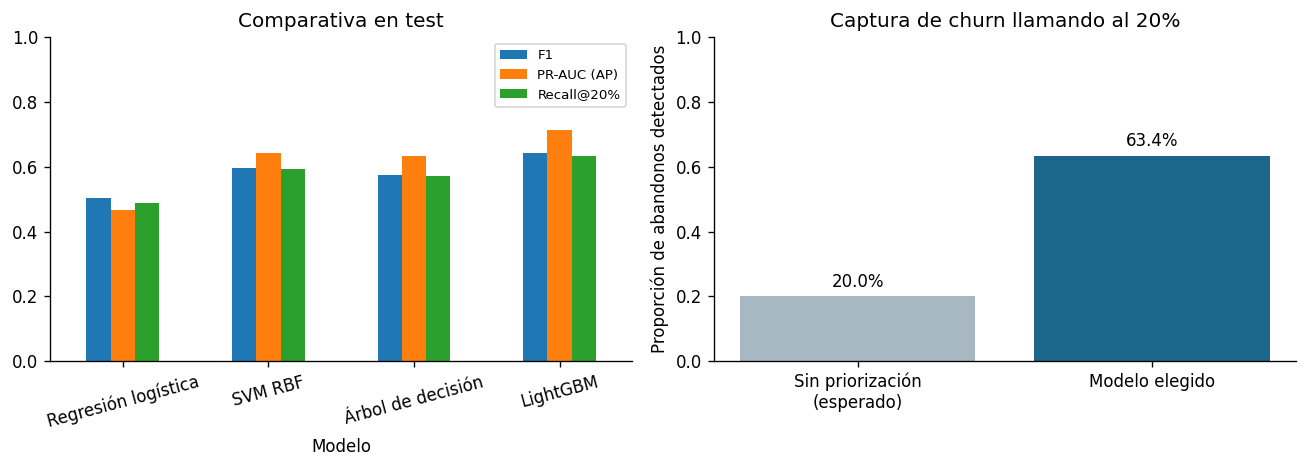

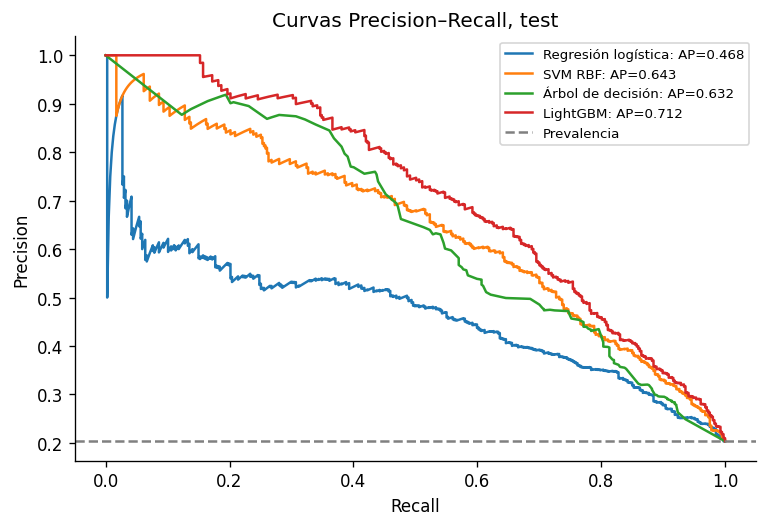

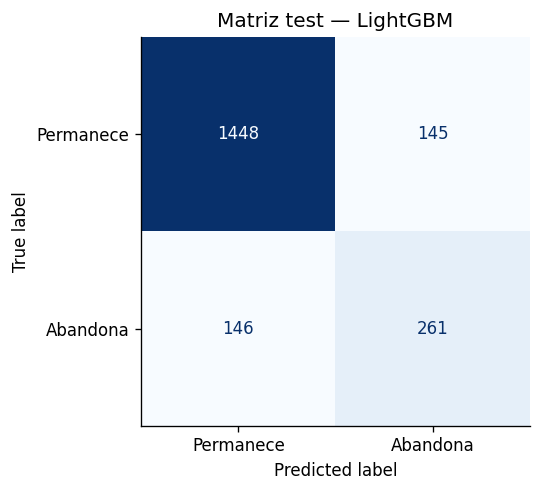

In [ ]:
ganador_score = scores_test[seleccionado]
cap = captura_top(y_test, ganador_score)
lift = cap['recall_top20']/0.20
print(f"Modelo: {seleccionado} | Contactados: {cap['contactados']}/{len(y_test)}")
print(f"Abandonos capturados: {cap['abandonos_detectados']} de {cap['abandonos_totales']}")
print(f"Captura@20%: {cap['recall_top20']:.2%} | Precision@20%: {cap['precision_top20']:.2%} | Lift frente a azar: {lift:.2f}x")
fig,axs=plt.subplots(1,2,figsize=(11,4))
tbl_plot=tabla_test.set_index('Modelo')[['F1','PR_AUC_AP','Captura20']]
tbl_plot.plot.bar(ax=axs[0],rot=15,ylim=(0,1),title='Comparativa en test')
axs[0].legend(['F1','PR-AUC (AP)','Recall@20%'],fontsize=8)
axs[1].bar(['Sin priorización\n(esperado)','Modelo elegido'],[.20,cap['recall_top20']],color=['#a7b8c2','#1c668b'])
axs[1].set_ylim(0,1);axs[1].set_ylabel('Proporción de abandonos detectados')
axs[1].set_title('Captura de churn llamando al 20%')
for i,v in enumerate([.20,cap['recall_top20']]):axs[1].text(i,v+.03,f'{v:.1%}',ha='center')
plt.tight_layout(); plt.savefig('comparacion_modelos.png',dpi=160,bbox_inches='tight');plt.show()

from sklearn.metrics import PrecisionRecallDisplay, ConfusionMatrixDisplay
fig,ax=plt.subplots(figsize=(6.5,4.5))
for nom, s in scores_test.items():
    p,r,_=precision_recall_curve(y_test,s)
    ax.plot(r,p,label=f'{nom}: AP={average_precision_score(y_test,s):.3f}')
ax.axhline(y_test.mean(),color='gray',linestyle='--',label='Prevalencia')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision');ax.set_title('Curvas Precision–Recall, test')
ax.legend(fontsize=8);plt.tight_layout();plt.savefig('curvas_pr.png',dpi=160,bbox_inches='tight');plt.show()
fig,ax=plt.subplots(figsize=(4.6,4.2))
ConfusionMatrixDisplay.from_predictions(y_test,y_pred_final,display_labels=['Permanece','Abandona'],
    ax=ax,cmap='Blues',colorbar=False)
ax.set_title(f'Matriz test — {seleccionado}');plt.tight_layout()
plt.savefig('matriz_confusion.png',dpi=160,bbox_inches='tight');plt.show()

### 9.1 Qué significa el resultado para Retención
Identificar una mayor proporción de clientes que abandonaron entre los casos priorizados permite **organizar el esfuerzo comercial** mejor que una selección aleatoria. Sin embargo, los datos disponibles **no muestran el efecto de llamar a esos clientes**, ni permiten afirmar ahorros, ROI o retención lograda.

La recomendación es validar primero con datos temporales y posteriormente con un experimento A/B antes de cualquier decisión de despliegue.

## 10. Análisis de sensibilidad, interpretación y limitaciones
La **preentrega** había dejado pendiente evaluar si el grupo reducido de clientes con **3–4 productos** condicionaba las métricas. Se estudia esa sensibilidad sin modificar el modelo ni usar el resultado para volver a seleccionar al ganador. Se observa además el comportamiento del ranking por segmentos para detectar posibles disparidades.

**Límites:** el dataset público no incluye fechas; su procedencia primaria y representatividad no están demostradas; no hay certeza de que todos los predictores se midieran antes del abandono; no existe validación prospectiva, ni costos por contacto, ni resultados de campañas. El valor comercial probado se limita a **identificación retrospectiva de riesgo**.

In [ ]:
# Robustez: mismo modelo y umbral (fijados), otro subgrupo del test.
mask = X_test['NumOfProducts'] <= 2
print('Clientes test con 1-2 productos:',int(mask.sum()),'de',len(mask))
print('F1 general:',round(f1_score(y_test,y_pred_final),4),
      '| F1 sin 3-4 productos:',round(f1_score(y_test[mask],y_pred_final[mask]),4))
print('AP general:',round(average_precision_score(y_test,ganador_score),4),
      '| AP sin 3-4 productos:',round(average_precision_score(y_test[mask],ganador_score[mask]),4))
priorizados = np.zeros(len(y_test),dtype=bool)
priorizados[np.argsort(-np.asarray(ganador_score),kind='mergesort')[:cap['contactados']]]=True
for variable in ['Geography','Gender']:
    diagnostico = pd.DataFrame({'grupo':X_test[variable].values,'abandona':y_test.values,
                                'priorizado':priorizados})
    resumen=diagnostico.groupby('grupo').apply(
        lambda d:pd.Series({'clientes':len(d),'churn_reales':int(d['abandona'].sum()),
        'capturados':int(d.loc[d.priorizado,'abandona'].sum()),
        'recall_top20_global':(d.loc[d.priorizado,'abandona'].sum()/max(d.abandona.sum(),1))}),
        include_groups=False)
    print('\nDiagnóstico descriptivo para',variable,'(cupo global compartido)')
    display(resumen.round(3))

Clientes test con 1-2 productos: 1931 de 2000
F1 general: 0.6421 | F1 sin 3-4 productos: 0.5877
AP general: 0.7117 | AP sin 3-4 productos: 0.6289

Diagnóstico descriptivo para Geography (cupo global compartido)


,clientes,churn_reales,capturados,recall_top20_global
grupo,,,,
France,1021.0,175.0,96.0,0.549
Germany,504.0,151.0,116.0,0.768
Spain,475.0,81.0,46.0,0.568



Diagnóstico descriptivo para Gender (cupo global compartido)


,clientes,churn_reales,capturados,recall_top20_global
grupo,,,,
Female,930.0,233.0,152.0,0.652
Male,1070.0,174.0,106.0,0.609


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/skle

/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/skle

/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/skle

/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/skle

/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Reducción media en AP
Age,0.2747
NumOfProducts,0.2653
IsActiveMember,0.1013
Balance,0.0548
Geography,0.0443
Gender,0.0066
Tenure,0.0015
HasCrCard,0.0008
CreditScore,-0.0002
BalanceZero,-0.0006


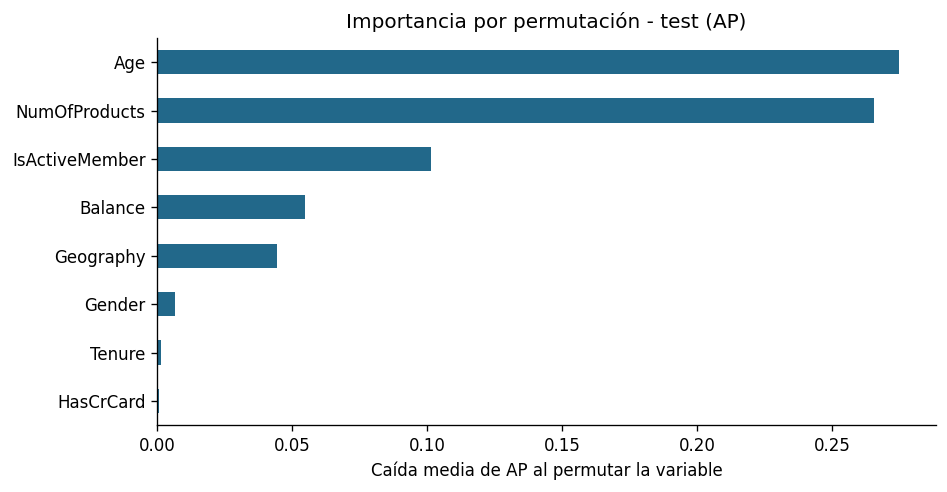

In [ ]:
# Importancia por permutación (variación de AP en test): diagnóstico descriptivo, no para elegir modelo.
from sklearn.inspection import permutation_importance
importancias = permutation_importance(
    modelos_entrenados[seleccionado], X_test, y_test, n_repeats=3,
    scoring='average_precision' if hasattr(modelos_entrenados[seleccionado],'predict_proba')
            else 'average_precision', random_state=42, n_jobs=1)
imp = pd.Series(importancias.importances_mean,index=X_test.columns).sort_values(ascending=False)
display(imp.to_frame('Reducción media en AP').round(4))
fig,ax=plt.subplots(figsize=(8,4.2))
imp.head(8).sort_values().plot.barh(ax=ax,color='#22688a')
ax.set_title('Importancia por permutación - test (AP)')
ax.set_xlabel('Caída media de AP al permutar la variable');plt.tight_layout()
plt.savefig('importancia_variables.png',dpi=160,bbox_inches='tight');plt.show()

### 10.1 Consideraciones éticas y próximos pasos
- Los clientes con tres o cuatro productos son pocos y tienen una tasa de abandono muy alta; por ello se presenta una **prueba de sensibilidad** sin reentrenar ni modificar el ganador.
- La importancia por permutación indica cuánto cambia la métrica al alterar una variable del **test observado**; no demuestra causalidad.
- El uso de `Gender`, `Age` y `Geography` exige revisar sesgos y evitar decisiones comerciales automáticas injustificadas.
- Antes de un uso real: verificar procedencia, licencia, protección de datos, disponibilidad temporal de los predictores, calibración, estabilidad y desempeño prospectivo.
- Como próxima etapa comercial: evaluar una campaña piloto A/B, con medición de contactos, resultados y costos.
- **Pendiente de la preentrega:** estudiar si excluir `EstimatedSalary` cambia materialmente el resultado. Se conserva en esta ejecución para mantener la comparabilidad de las métricas actuales.

## 11. Síntesis y materiales reproducibles
**Continuidad del trabajo:** partimos de la **preentrega aprobada con 90/100**, mantuvimos el problema y los cuatro algoritmos propuestos y aplicamos las correcciones docentes: train/test estratificado, validación cruzada, Precision/Recall/F1/PR-AUC, defensa del ganador y análisis del 20% de clientes priorizados.

**Criterio final:** selección según F1 de validación cruzada en entrenamiento; evaluación independiente en test. El valor comercial observado es la capacidad de **priorizar abandonos históricos**, no prevenirlos de manera demostrada. Las métricas concretas aparecen en la siguiente salida ejecutada para evitar desactualizaciones.

**Archivos que produce el notebook:** `resultados_validacion_cruzada.csv`, `resultados_test.csv`, `resumen_resultados_UTN.json`, `eda_segmentos.png`, `comparacion_modelos.png`, `curvas_pr.png`, `matriz_confusion.png` e `importancia_variables.png`.

**Preparación de la entrega:** el PDF de hasta 12 páginas (objetivo del grupo: **10 páginas**) deberá reflejar estas mismas cifras. Acompañar con el CSV original, instrucciones de reproducción y enlaces de acceso requeridos por la consigna. Las búsquedas históricas de `GridSearchCV` son antecedentes documentados; **no** aparecen como ejecuciones nuevas.

In [ ]:
ganador_test = tabla_test.set_index('Modelo').loc[seleccionado]
print(f"""CONCLUSIÓN
Modelo elegido por F1 de validación cruzada: {seleccionado}
CV — F1: {tabla_cv.iloc[0]['F1_CV_OOF']:.3f}; PR-AUC (AP): {tabla_cv.iloc[0]['PR_AUC_CV_OOF']:.3f}.
Test — Precision: {ganador_test['Precision']:.3f}; Recall: {ganador_test['Recall']:.3f};
       F1: {ganador_test['F1']:.3f}; PR-AUC (AP): {ganador_test['PR_AUC_AP']:.3f};
       ROC-AUC: {ganador_test['ROC_AUC']:.3f}.
Negocio — llamando al 20%, se detectan {cap['abandonos_detectados']} de {cap['abandonos_totales']} abandonos
          ({cap['recall_top20']:.1%}) versus 20% esperable al azar.
Meta orientativa F1>=0,60: {'CUMPLIDA' if ganador_test['F1']>=.6 else 'NO CUMPLIDA'};
Meta captura20>20%: {'CUMPLIDA' if cap['recall_top20']>.2 else 'NO CUMPLIDA'}.
""")
tabla_cv.to_csv('resultados_validacion_cruzada.csv',index=False)
tabla_test.to_csv('resultados_test.csv',index=False)
resumen = {'n_total':len(df),'n_train':len(y_train),'n_test':len(y_test),
           'churn_total':int(y.sum()),'prevalencia':float(y.mean()),
           'seleccionado':seleccionado, 'criterio':'F1 out-of-fold en CV 5 folds; desempate AP',
           'cv':tabla_cv.to_dict(orient='records'), 'test':tabla_test.to_dict(orient='records'),
           'negocio':{**cap, 'lift_vs_azar':lift},
           'confusion_test':confusion_matrix(y_test,y_pred_final).tolist(),
           'importancia_ap':imp.to_dict(),
           'robustez_sin_3_4_productos':{'n':int(mask.sum()),
              'F1':float(f1_score(y_test[mask],y_pred_final[mask])),
              'AP':float(average_precision_score(y_test[mask],ganador_score[mask]))}}
Path('resumen_resultados_UTN.json').write_text(json.dumps(resumen,ensure_ascii=False,indent=2),encoding='utf8')
print('Archivos guardados: resultados_validacion_cruzada.csv, resultados_test.csv, resumen_resultados_UTN.json, eda_segmentos.png y gráficos PNG de evaluación.')

CONCLUSIÓN
Modelo elegido por F1 de validación cruzada: LightGBM
CV — F1: 0.628; PR-AUC (AP): 0.693.
Test — Precision: 0.643; Recall: 0.641;
       F1: 0.642; PR-AUC (AP): 0.712;
       ROC-AUC: 0.867.
Negocio — llamando al 20%, se detectan 258 de 407 abandonos
          (63.4%) versus 20% esperable al azar.
Meta orientativa F1>=0,60: CUMPLIDA;
Meta captura20>20%: CUMPLIDA.

Archivos guardados: resultados_validacion_cruzada.csv, resultados_test.csv, resumen_resultados_UTN.json, eda_segmentos.png y gráficos PNG de evaluación.
